In [1]:
%precision 3
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as sl
from matplotlib import cm
import time

In [2]:
# THESE STAY THE SAME
def calculate_ppm_RHS(rho, u, v, RHS, dt, dx, dy):
    """ Calculate the RHS of the 
    Poisson equation resulting from the projection method.
    Use central differences for the first derivatives of u and v.
    """
    RHS[1:-1, 1:-1] = rho * (
        (1.0/dt) * ( (u[2:, 1:-1] - u[:-2, 1:-1]) / (2*dx) 
                   + (v[1:-1, 2:] - v[1:-1, :-2]) / (2*dy) )
        )
    return RHS


def project_velocity(rho, u, v, dt, dx, dy, p):
    """ Update the velocity to be divergence free using the pressure.
    """
    u[1:-1, 1:-1] = u[1:-1, 1:-1] - dt * (1./rho) * (
        (p[2:, 1:-1] - p[:-2, 1:-1])/(2*dx) )
    v[1:-1, 1:-1] = v[1:-1, 1:-1] - dt * (1./rho) * (
        (p[1:-1, 2:] - p[1:-1, :-2])/(2*dy) )    
    return u, v


def calculate_intermediate_velocity(nu, u, v, u_old, v_old, dt, dx, dy):
    """ Calculate the intermediate velocities.
    """
    # intermediate u
    u[1:-1, 1:-1] = u_old[1:-1, 1:-1] - dt * (
                      # ADVECTION:  uu_x + vu_x
                        u_old[1:-1, 1:-1] *
                      # see comments in the upwind based solver for advection above
                      np.select([u_old[1:-1, 1:-1] > 0, u_old[1:-1, 1:-1] < 0],
                      [np.diff(u_old[:-1, 1:-1], n=1, axis=0)/dx,
                       np.diff(u_old[1:, 1:-1], n=1, axis=0)/dx]) +
                             v_old[1:-1, 1:-1] *
                       np.select([v_old[1:-1, 1:-1] > 0, v_old[1:-1, 1:-1] < 0],
                      [np.diff(u_old[1:-1, :-1], n=1, axis=1)/dy,
                       np.diff(u_old[1:-1, 1:], n=1, axis=1)/dy]) ) + (
                       # DIFFUSION
                         dt*nu*(np.diff(u_old[:, 1:-1], n=2, axis=0)/(dx**2)
                                 + np.diff(u_old[1:-1, :], n=2, axis=1)/(dy**2)) )
    # intermediate v
    v[1:-1, 1:-1] = v_old[1:-1, 1:-1] - dt * (
                      # ADVECTION:  uv_x + vv_x
                        u_old[1:-1, 1:-1] *
                      np.select([u_old[1:-1, 1:-1] > 0, u_old[1:-1, 1:-1] < 0],
                      [np.diff(v_old[:-1, 1:-1], n=1, axis=0)/dx,
                       np.diff(v_old[1:, 1:-1], n=1, axis=0)/dx]) +
                             v_old[1:-1, 1:-1] *
                       np.select([v_old[1:-1, 1:-1] > 0, v_old[1:-1, 1:-1] < 0],
                      [np.diff(v_old[1:-1, :-1], n=1, axis=1)/dy,
                       np.diff(v_old[1:-1, 1:], n=1, axis=1)/dy]) ) + (
                       # DIFFUSION
                        dt*nu*(np.diff(v_old[:, 1:-1], n=2, axis=0)/(dx**2)
                                 + np.diff(v_old[1:-1, :], n=2, axis=1)/(dy**2)) )
    return u, v

In [3]:
def apply_temperature_BCs(T, T_inlet, T_wall, inlet_index):
    """Apply temperature boundary conditions."""
    
    # Top wall (left half) -> fixed temperature
    T[0, :inlet_index] = T_inlet
    # Top wall (right half) -> fixed temperature
    T[0, inlet_index:] = T_wall

    
    T[:, 0] = T_wall  # Bottom wall -> fixed temperature
    T[0, :] = T_wall  # Left wall -> fixed temperature
    
    # Right wall -> zero gradient
    T[-1, :] = T[-2, :]
    
    return T

In [ ]:
def update_temperature(T, u, v, rho, Cp, k_thermal, q, dt, dx, dy, inlet_index, T_inlet, T_wall):
    """Update the temperature field and enforce boundary conditions.
    """

    # slices of the temperature grid for easier calculation (alternative to np.diff)
    T_c = T[1:-1, 1:-1]  # Center
    T_l = T[0:-2, 1:-1]  # Left
    T_r = T[2:, 1:-1]    # Right
    T_b = T[1:-1, 0:-2]  # Bottom
    T_t = T[1:-1, 2:]    # Top
    
    # interior velocity
    u_c = u[1:-1, 1:-1]
    v_c = v[1:-1, 1:-1]
    
    # choose forward or backward difference for advection based on flow direction (upwind scheme)
    dT_dx = np.where(u_c > 0, T_c - T_l, T_r - T_c) / dx
    dT_dy = np.where(v_c > 0, T_c - T_b, T_t - T_c) / dy
    
    advection = -u_c * dT_dx - v_c * dT_dy
    
    # Diffusion
    d2T_dx2 = (T_r + T_l - 2*T_c) / (dx**2)
    d2T_dy2 = (T_t + T_b - 2*T_c) / (dy**2)
    diffusion = (k_thermal / (rho * Cp)) * (d2T_dx2 + d2T_dy2)
    
    # Update interior
    T_new = T.copy()
    T_new[1:-1, 1:-1] = T_c + dt * (advection + diffusion + q / (rho * Cp))
    
    return apply_temperature_BCs(T_new, T_inlet, T_wall, inlet_index)

In [5]:
def apply_velocity_BCs(u, v, in_idx):
    """ Apply velocity boundary conditions for microfluidic chamber.
    """
    # Bottom wall -> no-slip
    u[:, 0] = 0
    v[:, 0] = 0
    
    # Top wall (right half) -> no-slip
    u[in_idx:, -1] = 0
    v[in_idx:, -1] = 0
    
    # Top wall (left half) -> zero gradient
    u[:in_idx, -1] = u[:in_idx, -2]
    v[:in_idx, -1] = v[:in_idx, -2]

    # Left wall -> no-slip
    u[0, :] = 0
    v[0, :] = 0
    
    # Right wall -> zero gradient
    u[-1, :] = u[-2, :]
    v[-1, :] = v[-2, :]
    
    return u, v

In [6]:
def pressure_poisson_jacobi(p, dx, dy, RHS, p_in, p_out, in_idx, 
                            rtol=1.e-6, logs=False):
    """ Solve the pressure Poisson equation with pressure BCs at inlet/outlet.
    """

    tol = 10. * rtol
    it = 0
    p_old = np.copy(p)

    dx2 = dx * dx
    dy2 = dy * dy
    coeff = 1.0 / (2.0 / dx2 + 2.0 / dy2)
    
    while tol > rtol:
        temp = p_old
        p_old = p
        p = temp
        
        it += 1

        #* Interior points
        p[1:-1, 1:-1] = coeff * (
            (p_old[2:, 1:-1] + p_old[:-2, 1:-1]) / dx2 +
            (p_old[1:-1, 2:] + p_old[1:-1, :-2]) / dy2 -
            RHS[1:-1, 1:-1]
        )
        
        
        #* BCs
        # Bottom wall -> zero gradient
        p[:, 0] = p[:, 1]
        
        # Top wall (left half) -> constant pressure
        p[:in_idx, -1] = p_in

        # Top wall (right half) -> zero gradient
        p[in_idx:, -1] = p[in_idx:, -2]
        
        # Left wall -> zero gradient
        p[0, :] = p[1, :]
        
        # Right wall -> constant pressure
        p[-1, :] = p_out
        
        # Calculate tolerance
        tol = sl.norm(p - p_old) / np.maximum(1.0e-10, sl.norm(p))
        
    if logs: print('pressure solve iterations = {:4d}'.format(it))
    return p

In [7]:
def solve_NS(u, v, p, T, rho, nu, Cp, k_thermal, q, dt, t_end, 
                       dx, dy, p_in, p_out, inlet_index, T_inlet, T_wall,
                       rtol=1.e-6):
    """Solve incompressible NS with heat transfer."""
    t = 0
    u_old = u.copy()
    v_old = v.copy()
    T_old = T.copy()
    p_RHS = np.zeros_like(p)
    
    while t < t_end:
        t += dt
        
        # Calculate intermediate velocities
        u, v = calculate_intermediate_velocity(nu, u, v, u_old, v_old, dt, dx, dy)
        
        # Apply BCs to intermediate velocity
        u, v = apply_velocity_BCs(u, v, inlet_index)
        
        # Calculate RHS for pressure Poisson equation
        p_RHS = calculate_ppm_RHS(rho, u, v, p_RHS, dt, dx, dy)
        
        # Solve pressure with inlet/outlet BCs
        p = pressure_poisson_jacobi(p, dx, dy, p_RHS, p_in, p_out, 
                                   inlet_index, rtol)
        
        # Project velocity
        u, v = project_velocity(rho, u, v, dt, dx, dy, p)
        
        # Apply BCs after projection
        u, v = apply_velocity_BCs(u, v, inlet_index)
        
        # Update temperature
        T = update_temperature(T, u, v, rho, Cp, k_thermal, q, dt, dx, dy,
                              inlet_index, T_inlet, T_wall)
        
        # Check convergence
        tolu = sl.norm(u - u_old) / np.maximum(1.0e-10, sl.norm(u))
        tolv = sl.norm(v - v_old) / np.maximum(1.0e-10, sl.norm(v))
        tolT = sl.norm(T - T_old) / np.maximum(1.0e-10, sl.norm(T))
        
        if tolu < rtol and tolv < rtol and tolT < rtol:
            print('Converged at t = {:.8f}'.format(t))
            break
        
        # Swap arrays
        temp = u_old; u_old = u; u = temp
        temp = v_old; v_old = v; v = temp
        temp = T_old; T_old = T; T = temp


    max_vel = np.max(np.sqrt(u**2 + v**2))   
    print('Courant number criterion: {0:.7f}'.format(dx / max_vel))
    print('Diffusivity criterion: {0:.7f}'.format(rho * Cp * dx**2 / (2*k_thermal)))
    
    print('Temperature range: [{0:.2f}, {1:.2f}]°C'.format(np.min(T), np.max(T)))

    return u, v, p, T

In [8]:
# Physical parameters
Lx = 0.001
Ly = 0.0005
rho = 1000.0
mu = 0.001
nu = mu / rho

# Heat parameters
Cp = 4200.0
k_thermal = 0.6

# Initial conditions
T_in = 20.0
T_wall = 100.0

def init_sim(Nx=61, Ny=31, p_in=0.01, microwave_power=2000.0):

    # hence the mesh spacing
    dx = Lx/(Nx-1)
    dy = Ly/(Ny-1)

    X, Y = np.mgrid[0:Nx:1, 0:Ny:1]
    X = dx*X
    Y = dy*Y

    # initialise independent variables
    u = np.zeros_like(X)
    v = np.zeros_like(X)
    p = np.zeros_like(X)

    # Bottom wall -> no slip
    u[:, 0] = 0
    v[:, 0] = 0

    # Top wall (right half) -> no slip
    right_half_idx = Nx // 2

    u[right_half_idx:, -1] = 0
    v[right_half_idx:, -1] = 0

    # Top wall (left half)
    u[:right_half_idx, -1] = 0
    v[:right_half_idx, -1] = 0

    # Left wall -> no slip
    u[0, :] = 0
    v[0, :] = 0

    # Right wall
    u[:-1, :] = 0
    v[:-1, :] = 0

    p_out = 0.0

    # linear distribution to start with
    # for i in range(Nx):
    #     p[i, :] = p_in * (1 - X[i, 0]/Lx)

    p[:, :] = p_in

    # Right wall
    p[-1, :] = p_out

    #* Heat Transfer
    q = microwave_power / (Lx * Ly)

    # Initialize temperature field
    T = np.zeros_like(X)

    # Initial guess as inlet T
    T[:, :] = T_in

    # Apply wall boundary conditions
    T[:, 0] = T_wall  # Bottom wall
    T[right_half_idx:, -1] = T_wall  # Top wall (right half)
    T[:right_half_idx, -1] = T_in  # Top wall (left half)
    T[0, :] = T_wall  # Left wall

    return u, v, p, T, q, dx, dy, p_in, p_out, X, Y, Nx, Ny

In [ ]:
def plot_params(X, Y, p, T, u, v):
    """Plots the velocity, pressure and temperature fields."""
    # set up figure
    fig = plt.figure(figsize=(21, 16))
    ax1 = fig.add_subplot(221)
    cont = ax1.contourf(X, Y, p, levels=100, cmap=cm.viridis)
    fig.colorbar(cont)
    # don't plot at every grid point - every 5th
    ax1.quiver(X[::5,::5],Y[::5,::5],u[::5,::5],v[::5,::5])

    x_min, x_max = 0, Lx
    y_min, y_max = 0, Ly

    ax1.set_xlim(x_min, x_max)
    ax1.set_ylim(y_min, y_max)
    ax1.set_xlabel('$x$', fontsize=16)
    ax1.set_ylabel('$y$', fontsize=16)
    ax1.set_title('Heating chamber - pressure and velocity vectors', fontsize=16)

    ax1 = fig.add_subplot(222)
    cont = ax1.contourf(X, Y, np.sqrt(u*u+v*v), levels=100, cmap=cm.viridis)
    fig.colorbar(cont)
    ax1.set_xlim(x_min, x_max)
    ax1.set_ylim(y_min, y_max)
    ax1.set_xlabel('$x$', fontsize=16)
    ax1.set_ylabel('$y$', fontsize=16)
    ax1.set_title('Heating chamber - speed', fontsize=16)


    ax3 = fig.add_subplot(223)
    cont = ax3.contourf(X, Y, T, levels=50, cmap=cm.inferno) 
    fig.colorbar(cont, ax=ax3)
    ax3.set_xlim(x_min, x_max)
    ax3.set_ylim(y_min, y_max)
    ax3.set_xlabel('$x$', fontsize=16)
    ax3.set_ylabel('$y$', fontsize=16)
    ax3.set_title('Temperature', fontsize=16)

    plt.tight_layout()

In [ ]:
def mass_conservation(u, v, dx, dy, inlet_idx):
    """Calculate the volumetric inflow and outflow rates
    by integrating over the inflow and outflow boundaries."""
    # Inlet
    v_inlet = np.abs(v[:inlet_idx, -1])
    Q_in = np.trapezoid(v_inlet, dx=dx)

    # Outlet
    u_outlet = u[-1, :]
    Q_out = np.trapezoid(u_outlet, dx=dy)

    return Q_in, Q_out

In [ ]:
def calculate_out_flow_avg_temp(T, u, dy):
    """Calculates the flow average outflow temperature.
    """
    # T and u at the right wall
    T_out = T[-1, :]
    u_out = u[-1, :]
    
    flux = u_out * dy
    
    total_volume_flux = np.sum(flux)
    total_energy_flux = np.sum(T_out * flux)
    
    return total_energy_flux / total_volume_flux


def calculate_in_flow_avg_temp(T, u, dx, inlet_index):
    """
    Calculates the flow average inflow temperature.
    """
    T_in = T[:inlet_index, -1]
    u_in = u[:inlet_index, -1]

    flux = u_in * dx

    total_volume_flux = np.sum(flux)
    total_energy_flux = np.sum(T_in * flux)
    
    return total_energy_flux / total_volume_flux


def Re(u, Lx):
    """Calculates the Reynolds number of the system."""
    u_out = u[-1, :]
    u_avg = np.mean(u_out)

    return (rho * u_avg * Lx) / mu

def Pe(re):
    """Calculates the Peclet number of the system."""
    return re * mu * Cp / k_thermal

def Da(q, Lx, T_rise, rho, Cp, u):
    """Calculates the Damkohler number of the system."""
    u_out = u[-1, :]
    u_avg = np.mean(u_out)

    return q * Lx / (rho * Cp * u_avg * T_rise)

I use the length of the horizontal plate as the characteristic length and mean velocity at the outflow as characteristic velocity.

In [ ]:
def run_sim(Nx=151, Ny=75, p_in=0.01, microwave_power=2000.0):
    """Runs the simulation with specified number of grid points,
    pressure in the inlet and microwave power.
    """
    start = time.time()

    u, v, p, T, q, dx, dy, p_in, p_out, X, Y, Nx, Ny = init_sim(Nx, Ny, p_in, microwave_power)
    inlet_index = Nx // 2

    dt = 2.0e-6
    t_end = 0.1

    u, v, p, T = solve_NS(u, v, p, T, rho, nu, Cp, k_thermal, q, 
                                    dt, t_end, dx, dy, p_in, p_out, 
                                    inlet_index, T_in, T_wall)

    total_points = Nx*Ny
    print('Average x-velocity: {0:.2e} m/s, Average x-velocity: {1:.2e} m/s, Average temperature: {2:.1f} deg'.format(
        sl.norm(u)/np.sqrt(total_points), 
        sl.norm(v)/np.sqrt(total_points), 
        sl.norm(T)/np.sqrt(total_points)))

    end = time.time()
    print(f'Time taken by calculation = {(end - start):.4f}')


    plot_params(X, Y, p, T, u, v)

    out_flow = calculate_out_flow_avg_temp(T, u, dy)
    in_flow = calculate_in_flow_avg_temp(T, v, dx, inlet_index)
    re = Re(u, Lx)
    pe = Pe(re)
    da = Da(q, Lx, 80, rho, Cp, u)

    print(f"Out Flow: {out_flow:.2f} deg")
    print(f"In Flow: {in_flow:.2f} deg")
    print(f"Reynolds number: {re:.4f}")
    print(f"Peclet number: {pe:.4f}")
    print(f"Damkohler number: {da:.4f}")

    Q_in, Q_out = mass_conservation(u, v, dx, dy, inlet_index)
    print(f"Flow in Rate: {Q_in:.3e} m²/s")
    print(f"Flow out Rate: {Q_out:.3e} m²/s")

    return pe, out_flow

Courant number criterion: 0.0193618
Diffusivity criterion: 0.0001556
Temperature range: [20.00, 105.83]°C
Average x-velocity: 2.00e-04 m/s, Average x-velocity: 9.81e-05 m/s, Average temperature: 83.3 deg
Time taken by calculation = 40.9730
Out Flow: 81.57 deg
In Flow: 20.00 deg
Reynolds number: 0.2263
Peclet number: 1.5843
Damkohler number: 52.5999
Flow in Rate: 1.138e-07 m²/s
Flow out Rate: 1.147e-07 m²/s


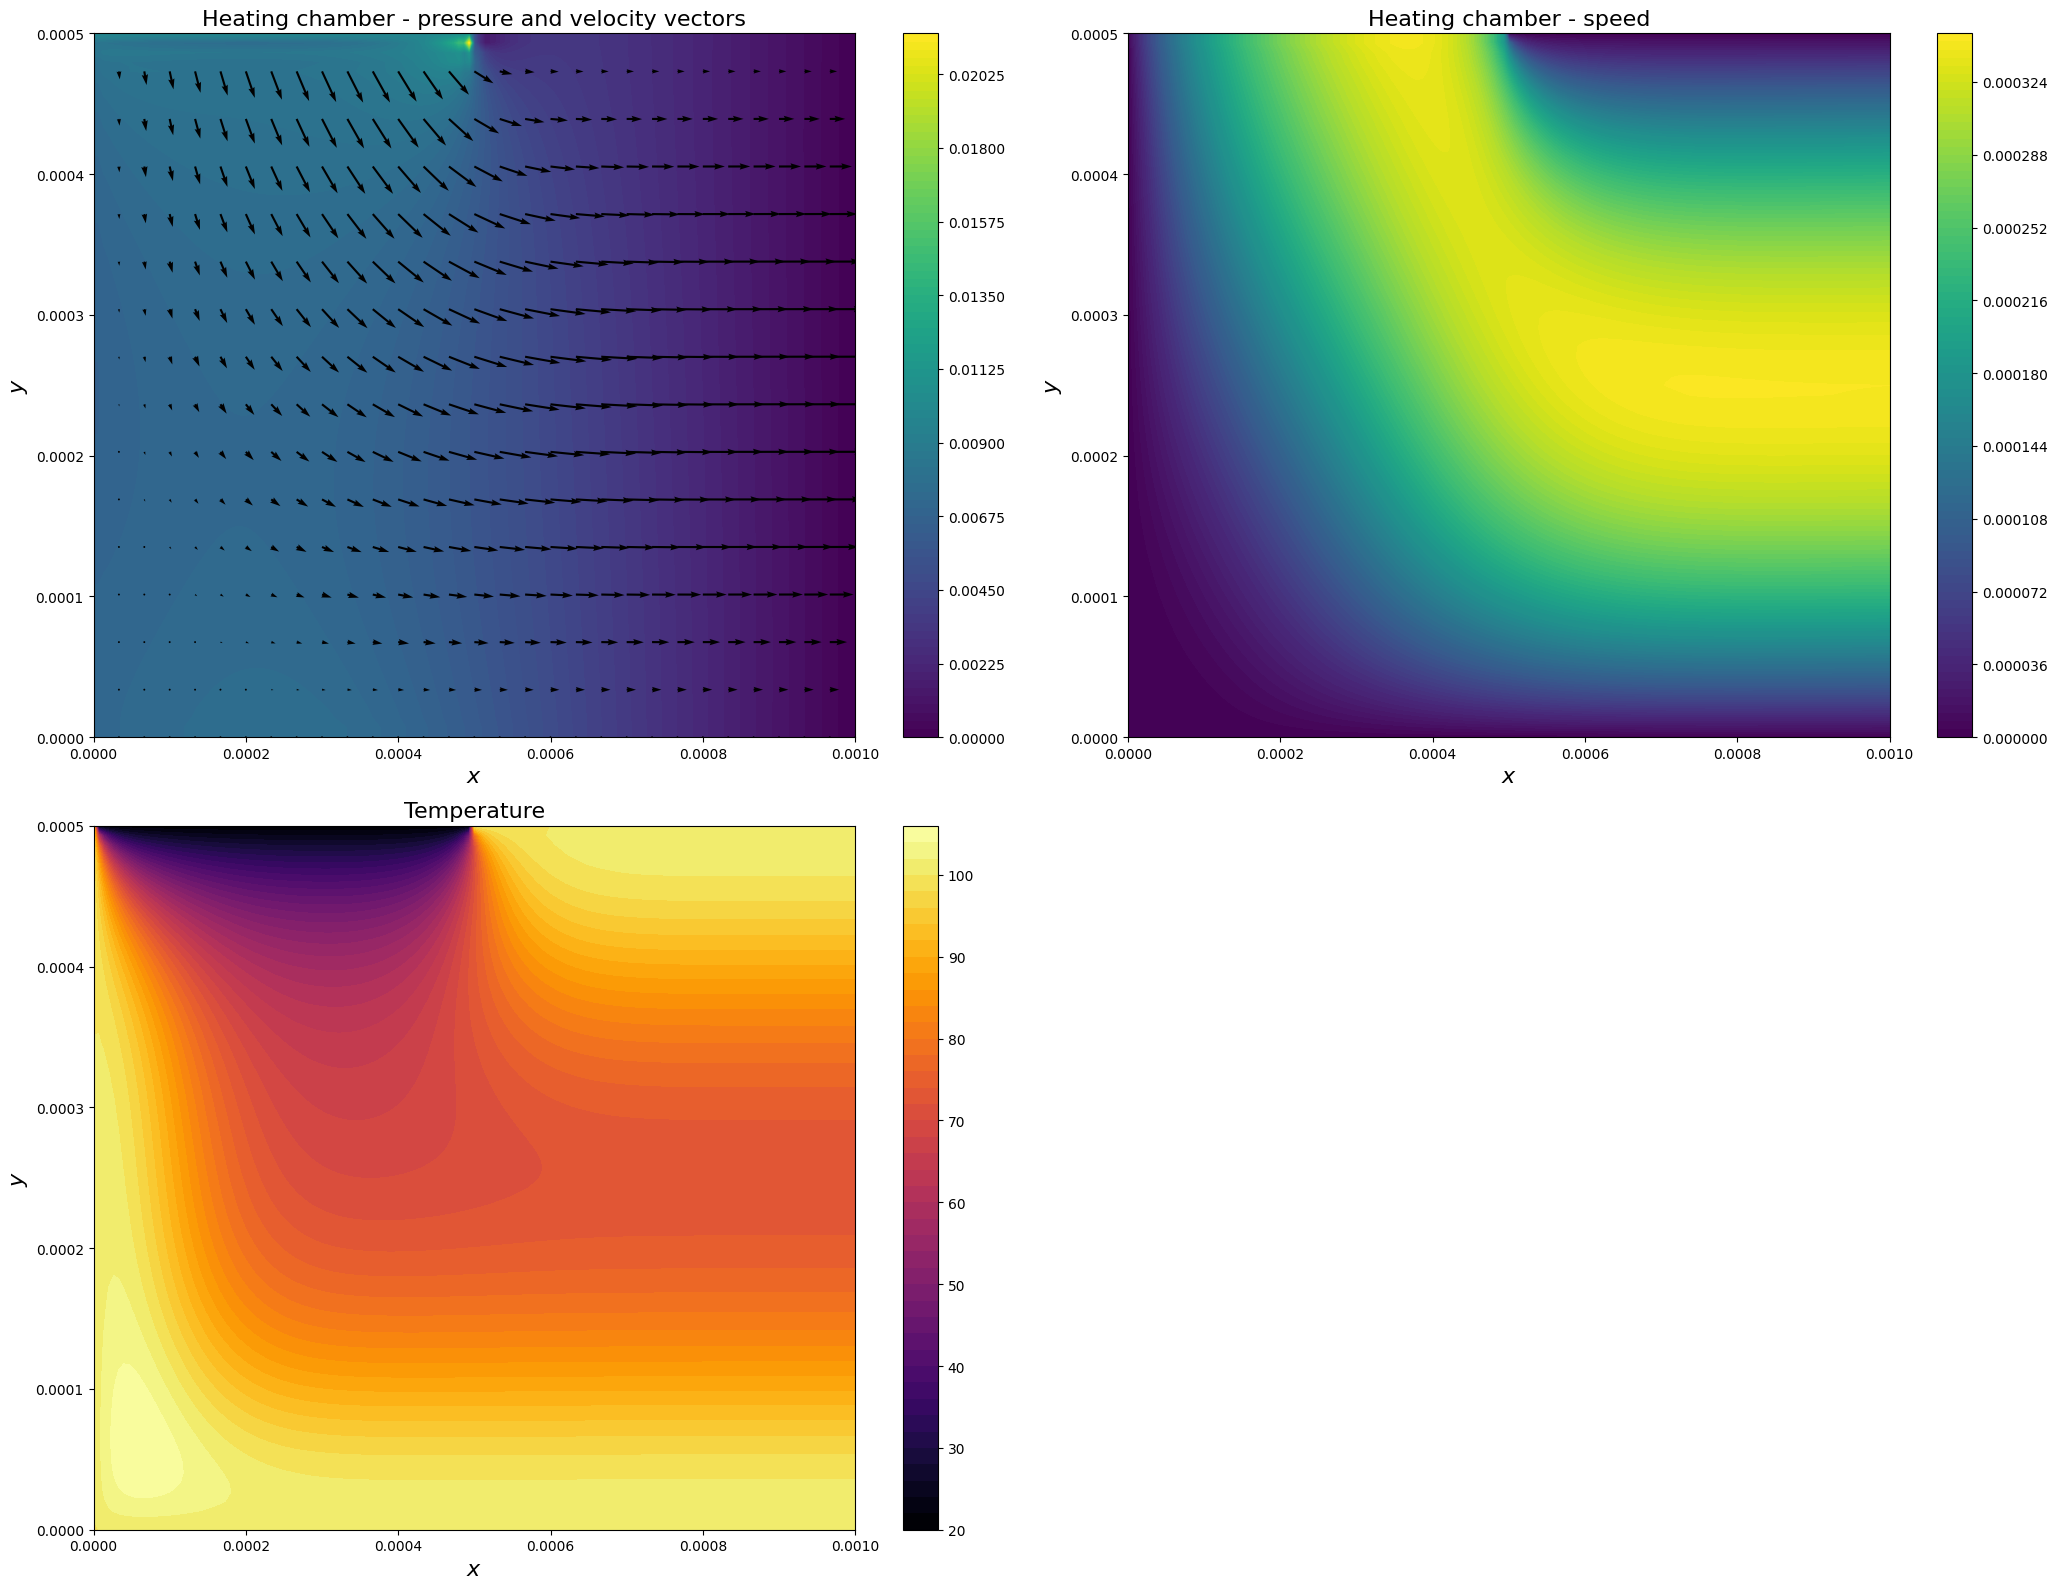

In [13]:
pe_1, out_flow_1 = run_sim(p_in=0.01)

Pressure solve iterations decrease over time as expected. Although the Courant number is much larger than dt, the diffusivity criterion is more restrictive at these scales.

The average inflow temperature is equal to 20 (that's the boundary condition) and is much smaller than the outflow one, since heat is added to the flow through walls and microwave radiation.

### Re and Pe
The two dimensionless groups are the Reynolds and Peclet numbers. I will increase the pressure difference between the inlet and outlet to see how the results change.

Courant number criterion: 0.0019301
Diffusivity criterion: 0.0001556
Temperature range: [20.00, 105.84]°C
Average x-velocity: 1.98e-03 m/s, Average x-velocity: 9.81e-04 m/s, Average temperature: 82.0 deg
Time taken by calculation = 40.0485
Out Flow: 81.57 deg
In Flow: 20.00 deg
Reynolds number: 2.2487
Peclet number: 15.7412
Damkohler number: 5.2940
Flow in Rate: 1.130e-06 m²/s
Flow out Rate: 1.140e-06 m²/s


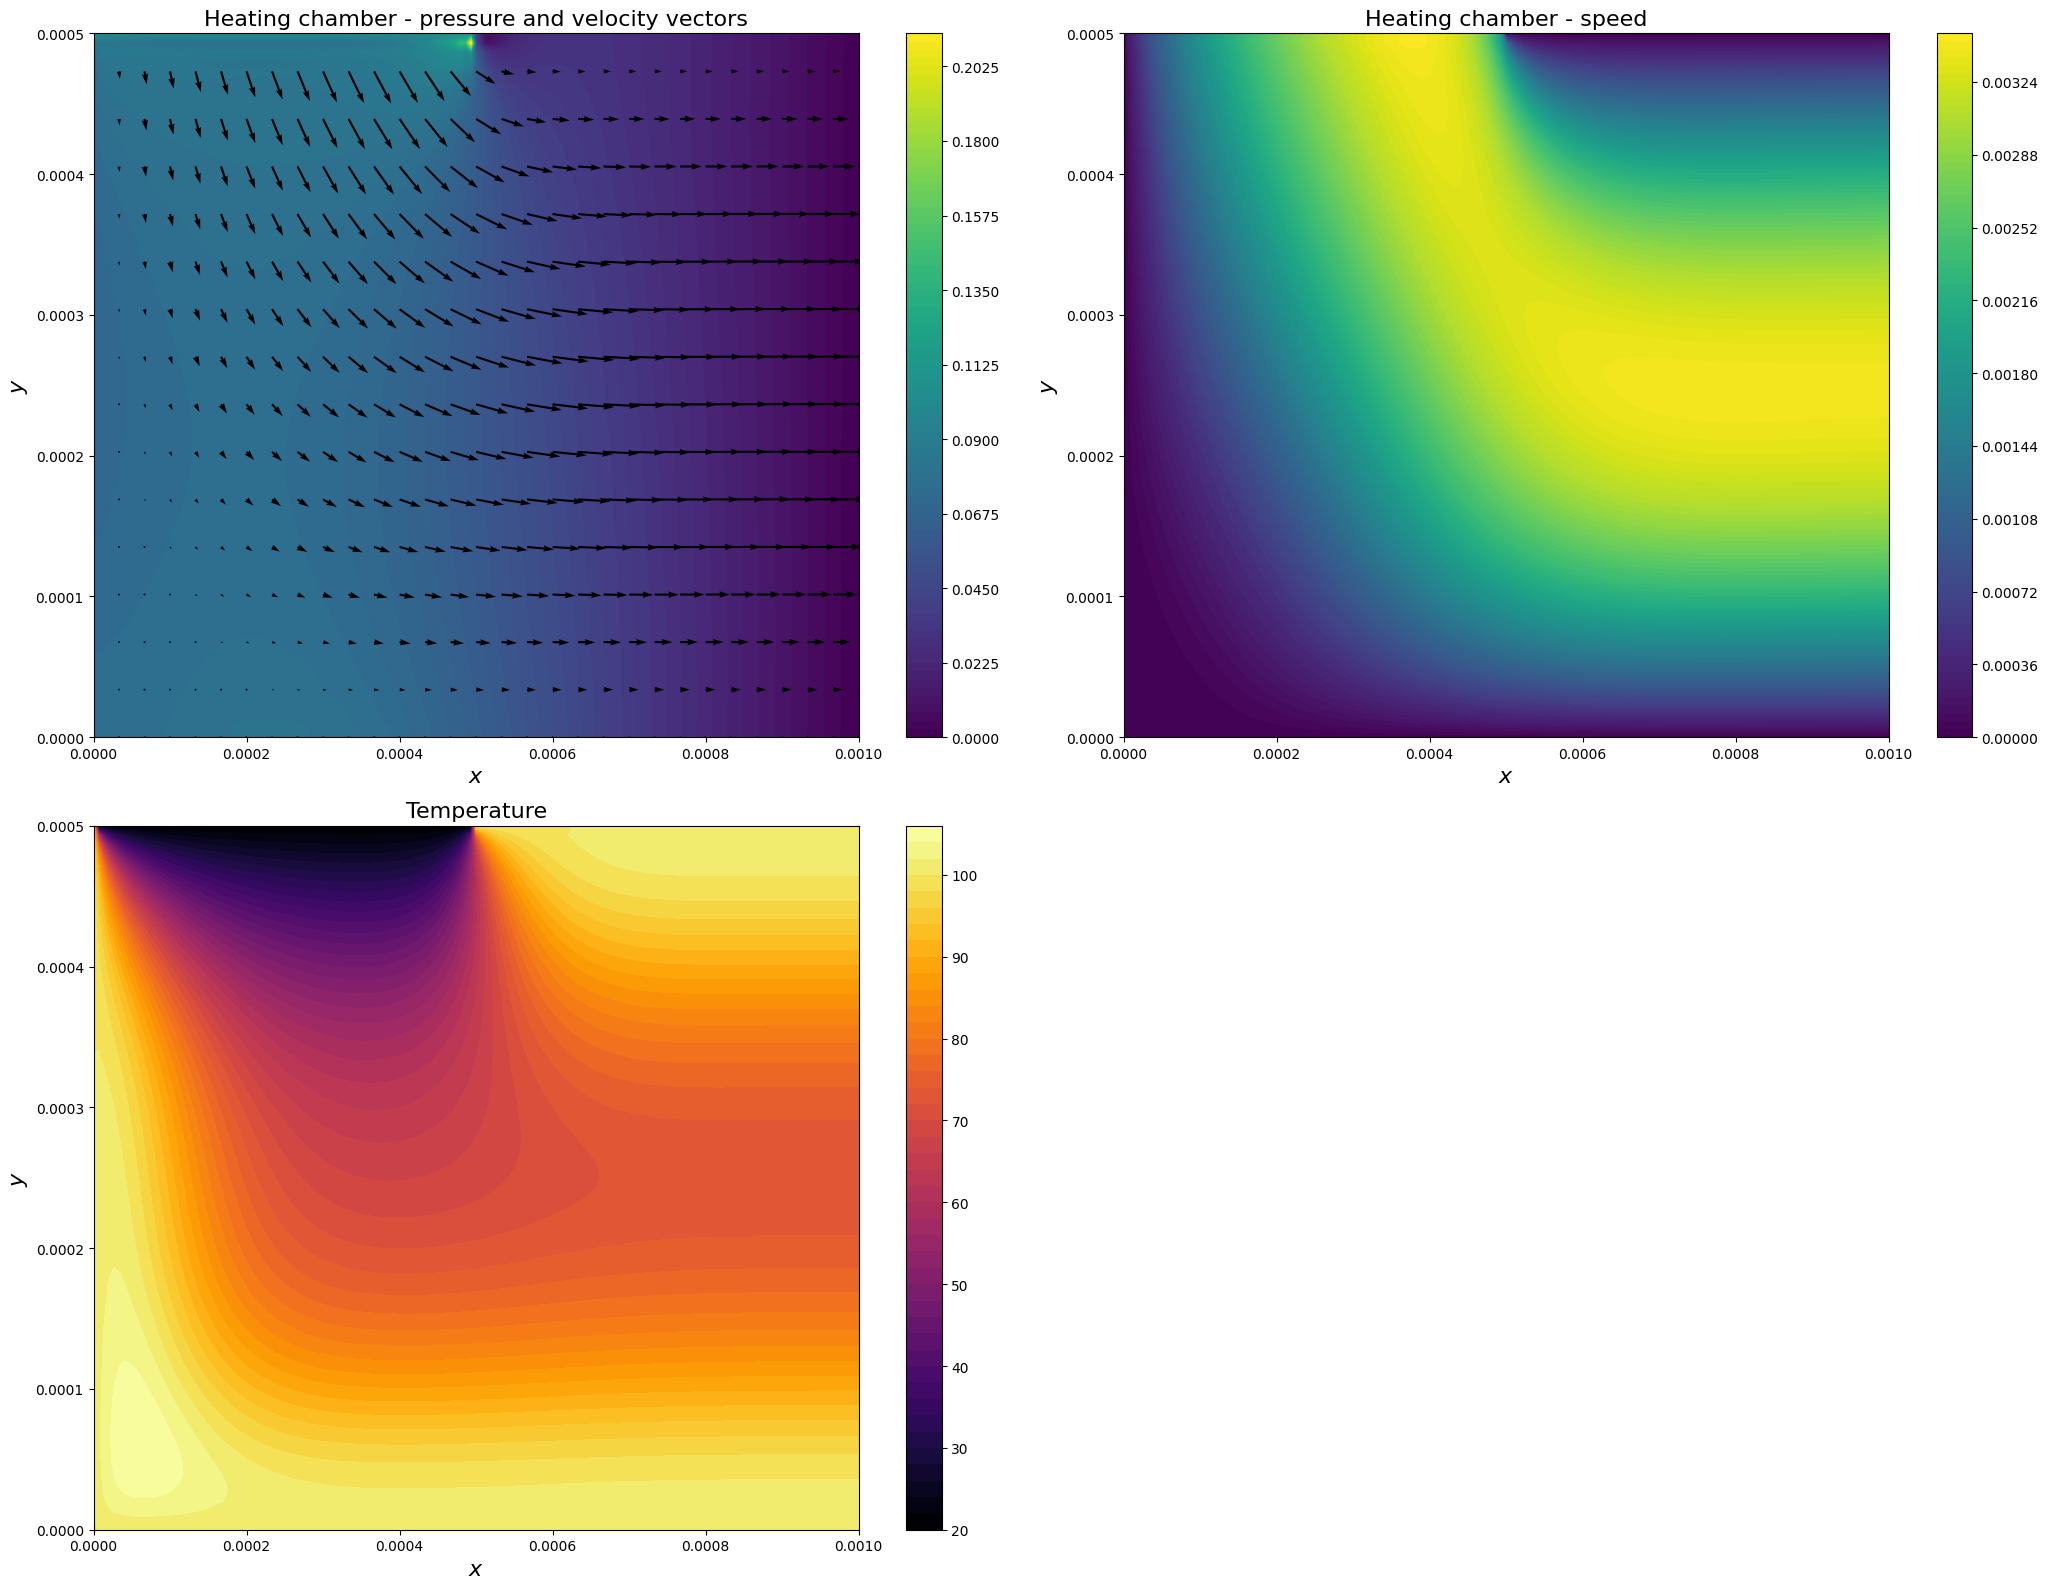

In [14]:
pe_2, out_flow_2 = run_sim(p_in=0.1)

Converged at t = 0.09834800
Courant number criterion: 0.0001636
Diffusivity criterion: 0.0001556
Temperature range: [20.00, 105.68]°C
Average x-velocity: 1.75e-02 m/s, Average x-velocity: 9.43e-03 m/s, Average temperature: 66.9 deg
Time taken by calculation = 46.9915
Out Flow: 63.29 deg
In Flow: 20.00 deg
Reynolds number: 20.2879
Peclet number: 142.0154
Damkohler number: 0.5868
Flow in Rate: 1.014e-05 m²/s
Flow out Rate: 1.028e-05 m²/s


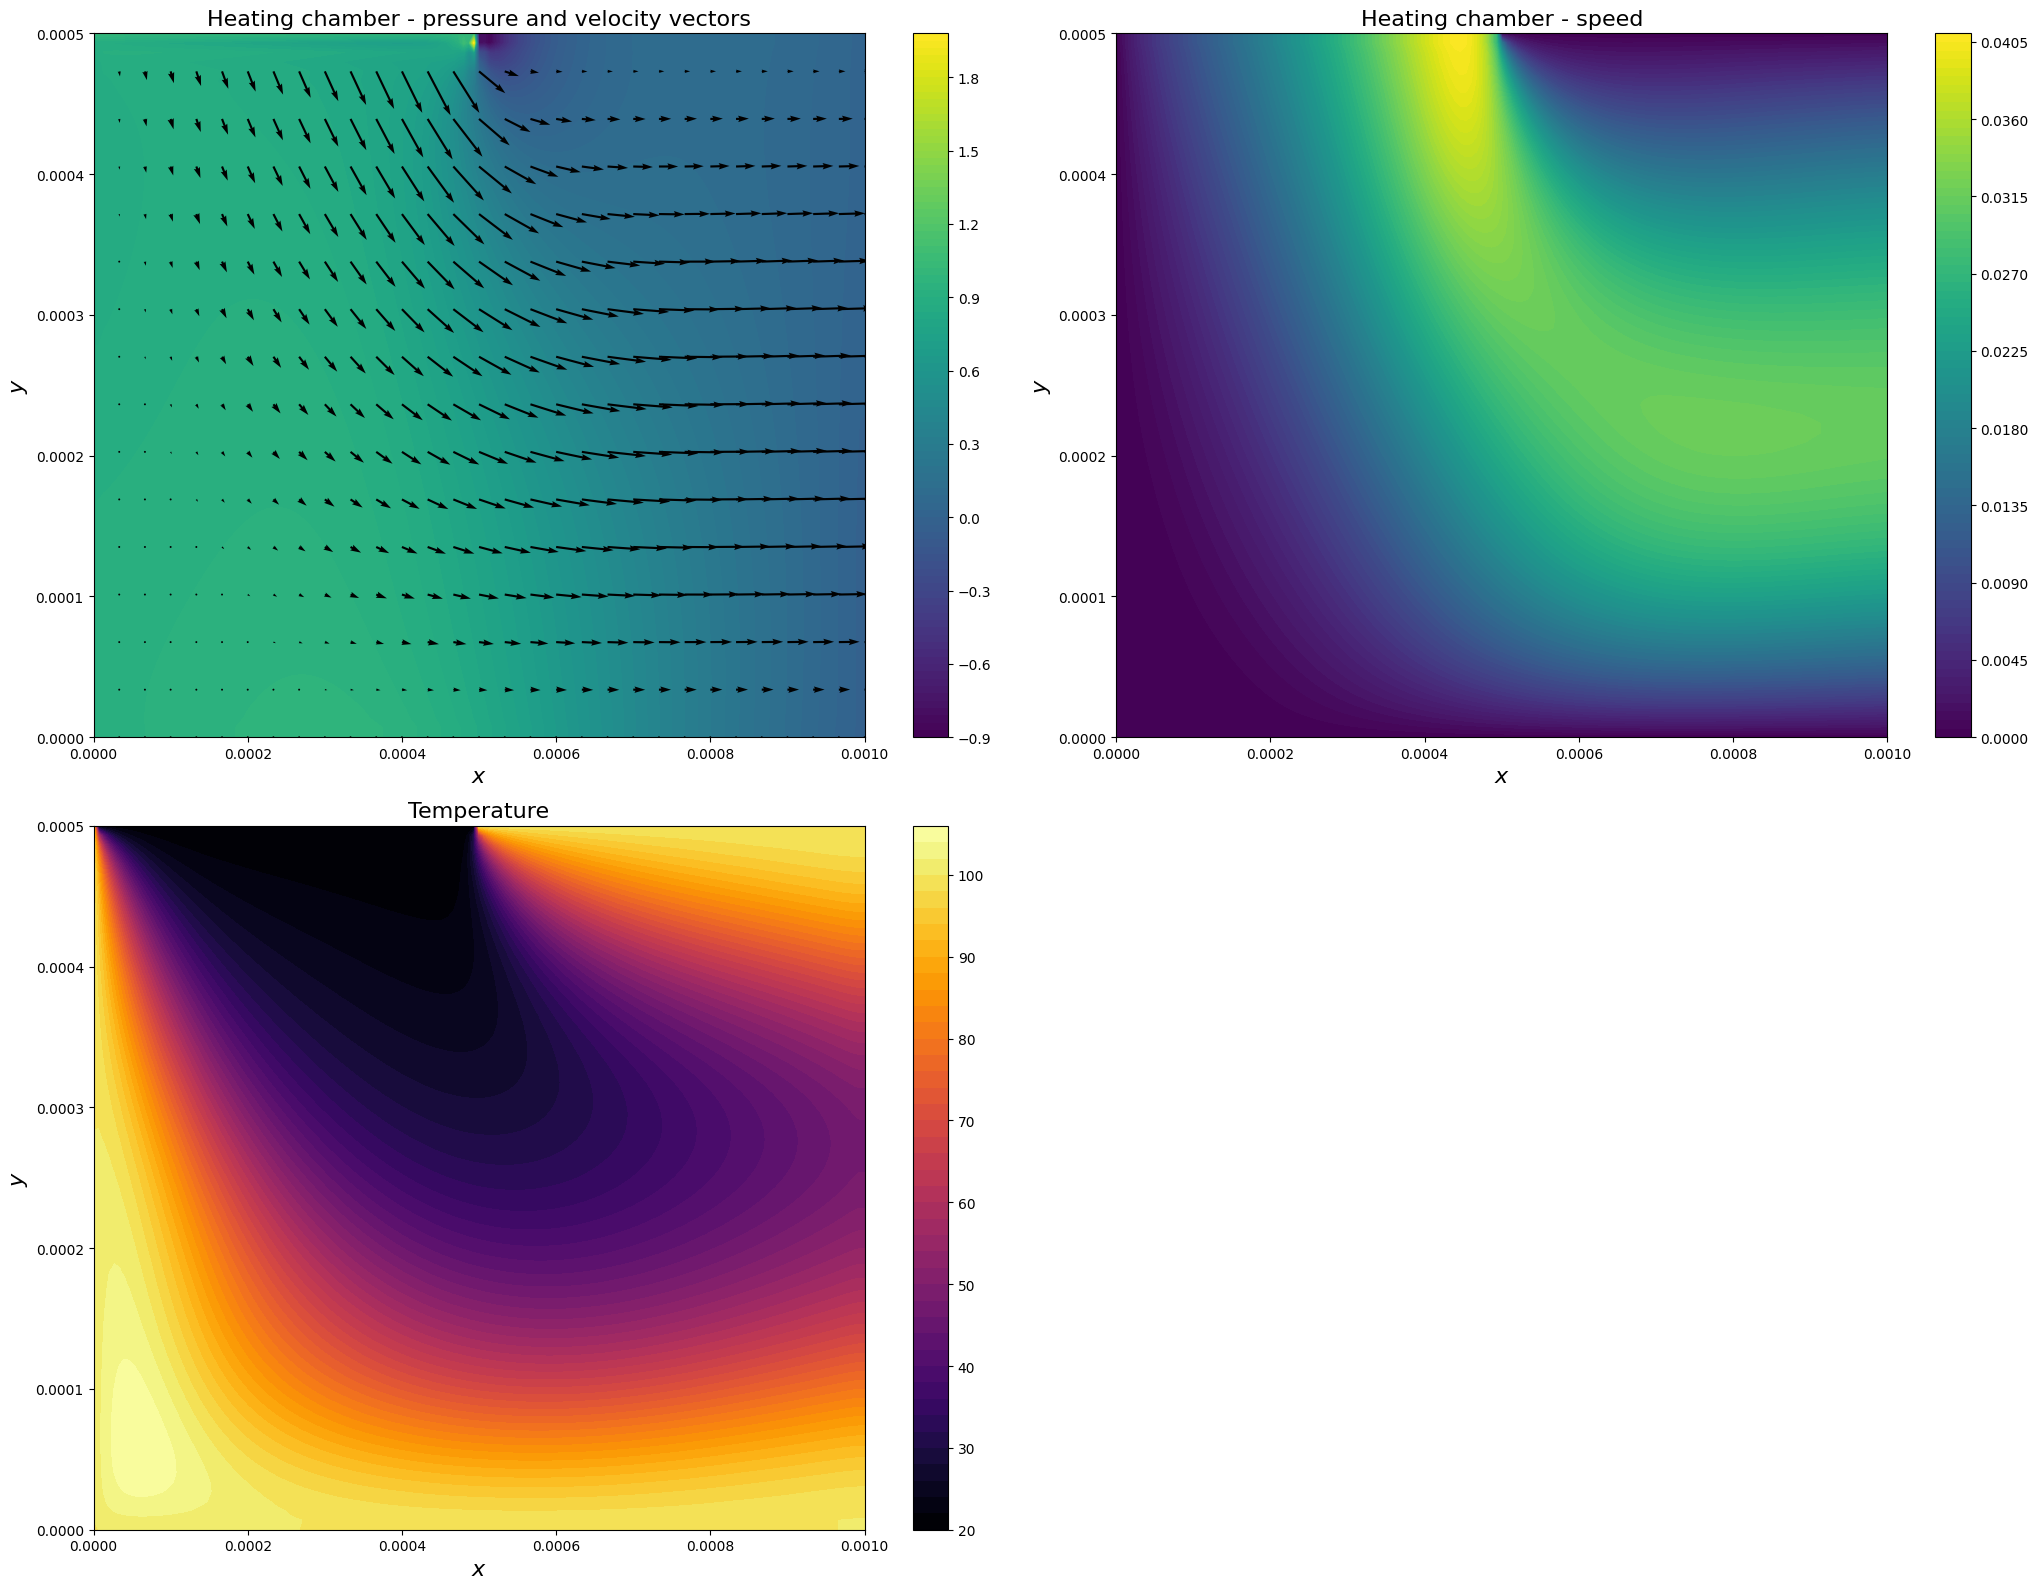

In [15]:
pe_3, out_flow_3 = run_sim(p_in=1)

Converged at t = 0.07147200
Courant number criterion: 0.0000175
Diffusivity criterion: 0.0001556
Temperature range: [20.00, 101.99]°C
Average x-velocity: 9.13e-02 m/s, Average x-velocity: 5.52e-02 m/s, Average temperature: 58.2 deg
Time taken by calculation = 82.8167
Out Flow: 34.71 deg
In Flow: 20.00 deg
Reynolds number: 98.9228
Peclet number: 692.4598
Damkohler number: 0.1203
Flow in Rate: 4.823e-05 m²/s
Flow out Rate: 5.013e-05 m²/s


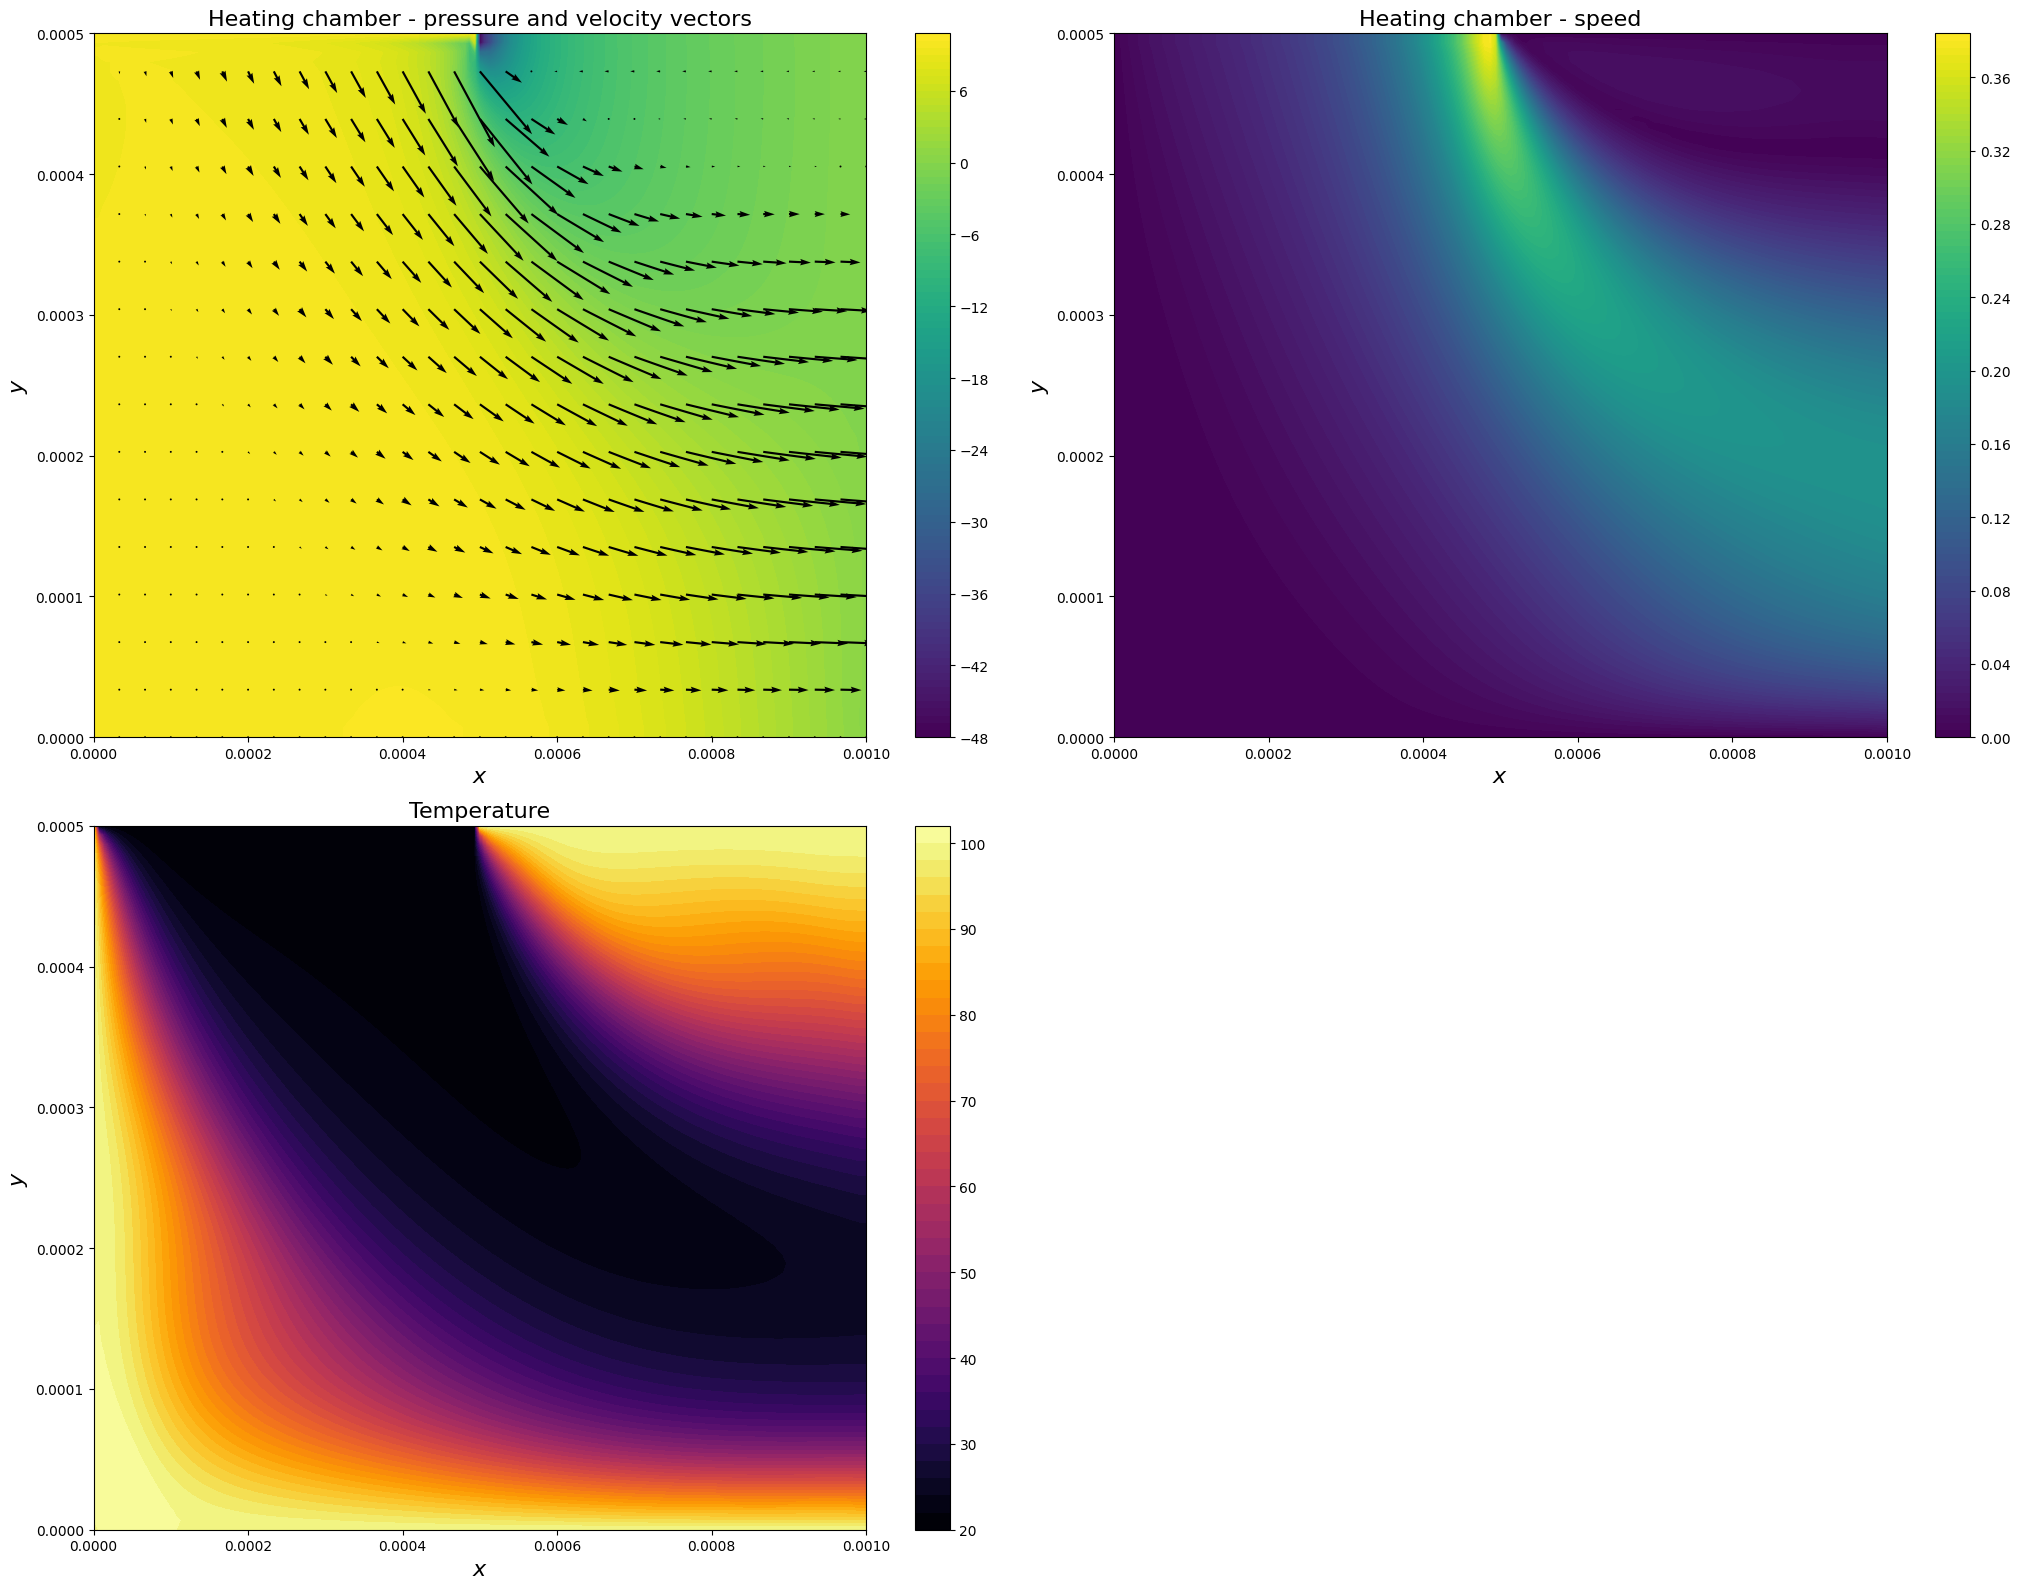

In [16]:
pe_4, out_flow_4 = run_sim(p_in=10)

### Analysis of flow at different Re and Pe

The first simulation with Pe = 1.3 number indicates a balanced regime, where both advection and diffusion are relatively important. The flow lines are smooth and gradients are smooth at the inlet. The flow is fully parabolic at the outlet. The temperature spreads smoothly in all directions (including the direction of flow), fluid remains in the device long enough for heat to penetrate it. This is probably prefered in systems engineering for optimal transport efficiency.

In the case of simulations at Pe >> 1, the flow is dominated by advection, meaning there's not enough time for water to be penetrated by the heat, indicated by a much lower average temperature outflow (81.57 deg vs 35.58 deg). The velocity profile is skewed towards the bottom of the chamber.

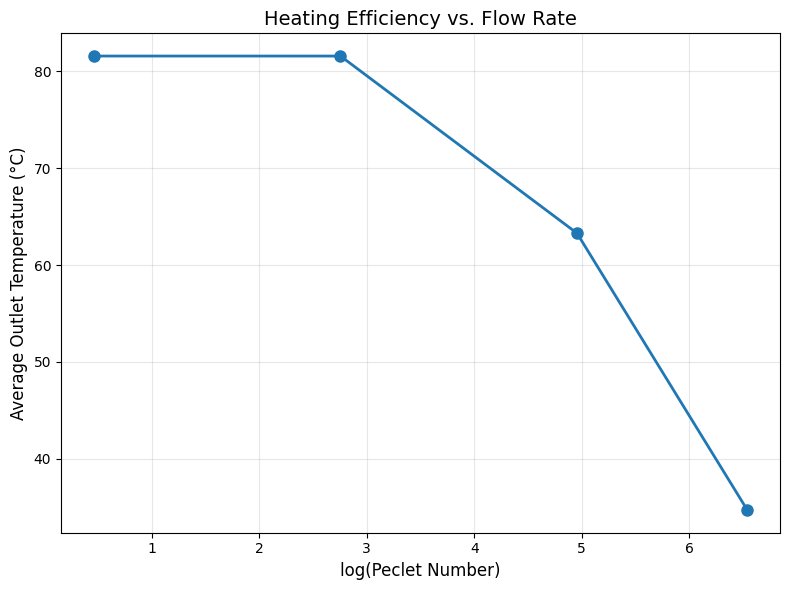

In [17]:
pe_nums = [pe_1, pe_2, pe_3, pe_4]
out_flow_nums = [out_flow_1, out_flow_2, out_flow_3, out_flow_4]

plt.figure(figsize=(8, 6))
plt.plot(np.log(pe_nums), out_flow_nums, 'o-', linewidth=2, markersize=8)
plt.xlabel('log(Peclet Number)', fontsize=12)
plt.ylabel('Average Outlet Temperature (°C)', fontsize=12)
plt.title('Heating Efficiency vs. Flow Rate', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The graph shows that average outlet temperature decreases with peclet number. This is consistent with theory, since advection dominated flow would not receive as much heat from conduction (at constant microwave input), as during conduction-dominated regime.

### Inlet interface

The checkerboard pattern of high and low pressure fields is visible (and is more pronounced at higher dx/dy) near the inlet, caused by the co-located pressure and velocity nodes. Additioinally, at high Re number there appears large pressure difference at the interface of inlet and no-slip boundaries, likely caused by the imposed boundary conditions.

NB: The CFL condition starts to dominate at higher Re, since velocities are larger due to larger pressure difference.

### Damkohler number

Another dimensionless group is the Damkohler number, which is the ratio between the heating and transport (advection) rates. I change Da by varying the microwave power density. The desired temperature rise is taken as the difference between wall temperatures and inflow temperature ($100-20=80$ deg).

Courant number criterion: 0.0193618
Diffusivity criterion: 0.0001556
Temperature range: [20.00, 100.00]°C
Average x-velocity: 2.00e-04 m/s, Average x-velocity: 9.81e-05 m/s, Average temperature: 54.7 deg
Time taken by calculation = 40.5664
Out Flow: 40.48 deg
In Flow: 20.00 deg
Reynolds number: 0.2263
Peclet number: 1.5843
Damkohler number: 0.0263
Flow in Rate: 1.138e-07 m²/s
Flow out Rate: 1.147e-07 m²/s


(1.584, 40.477)

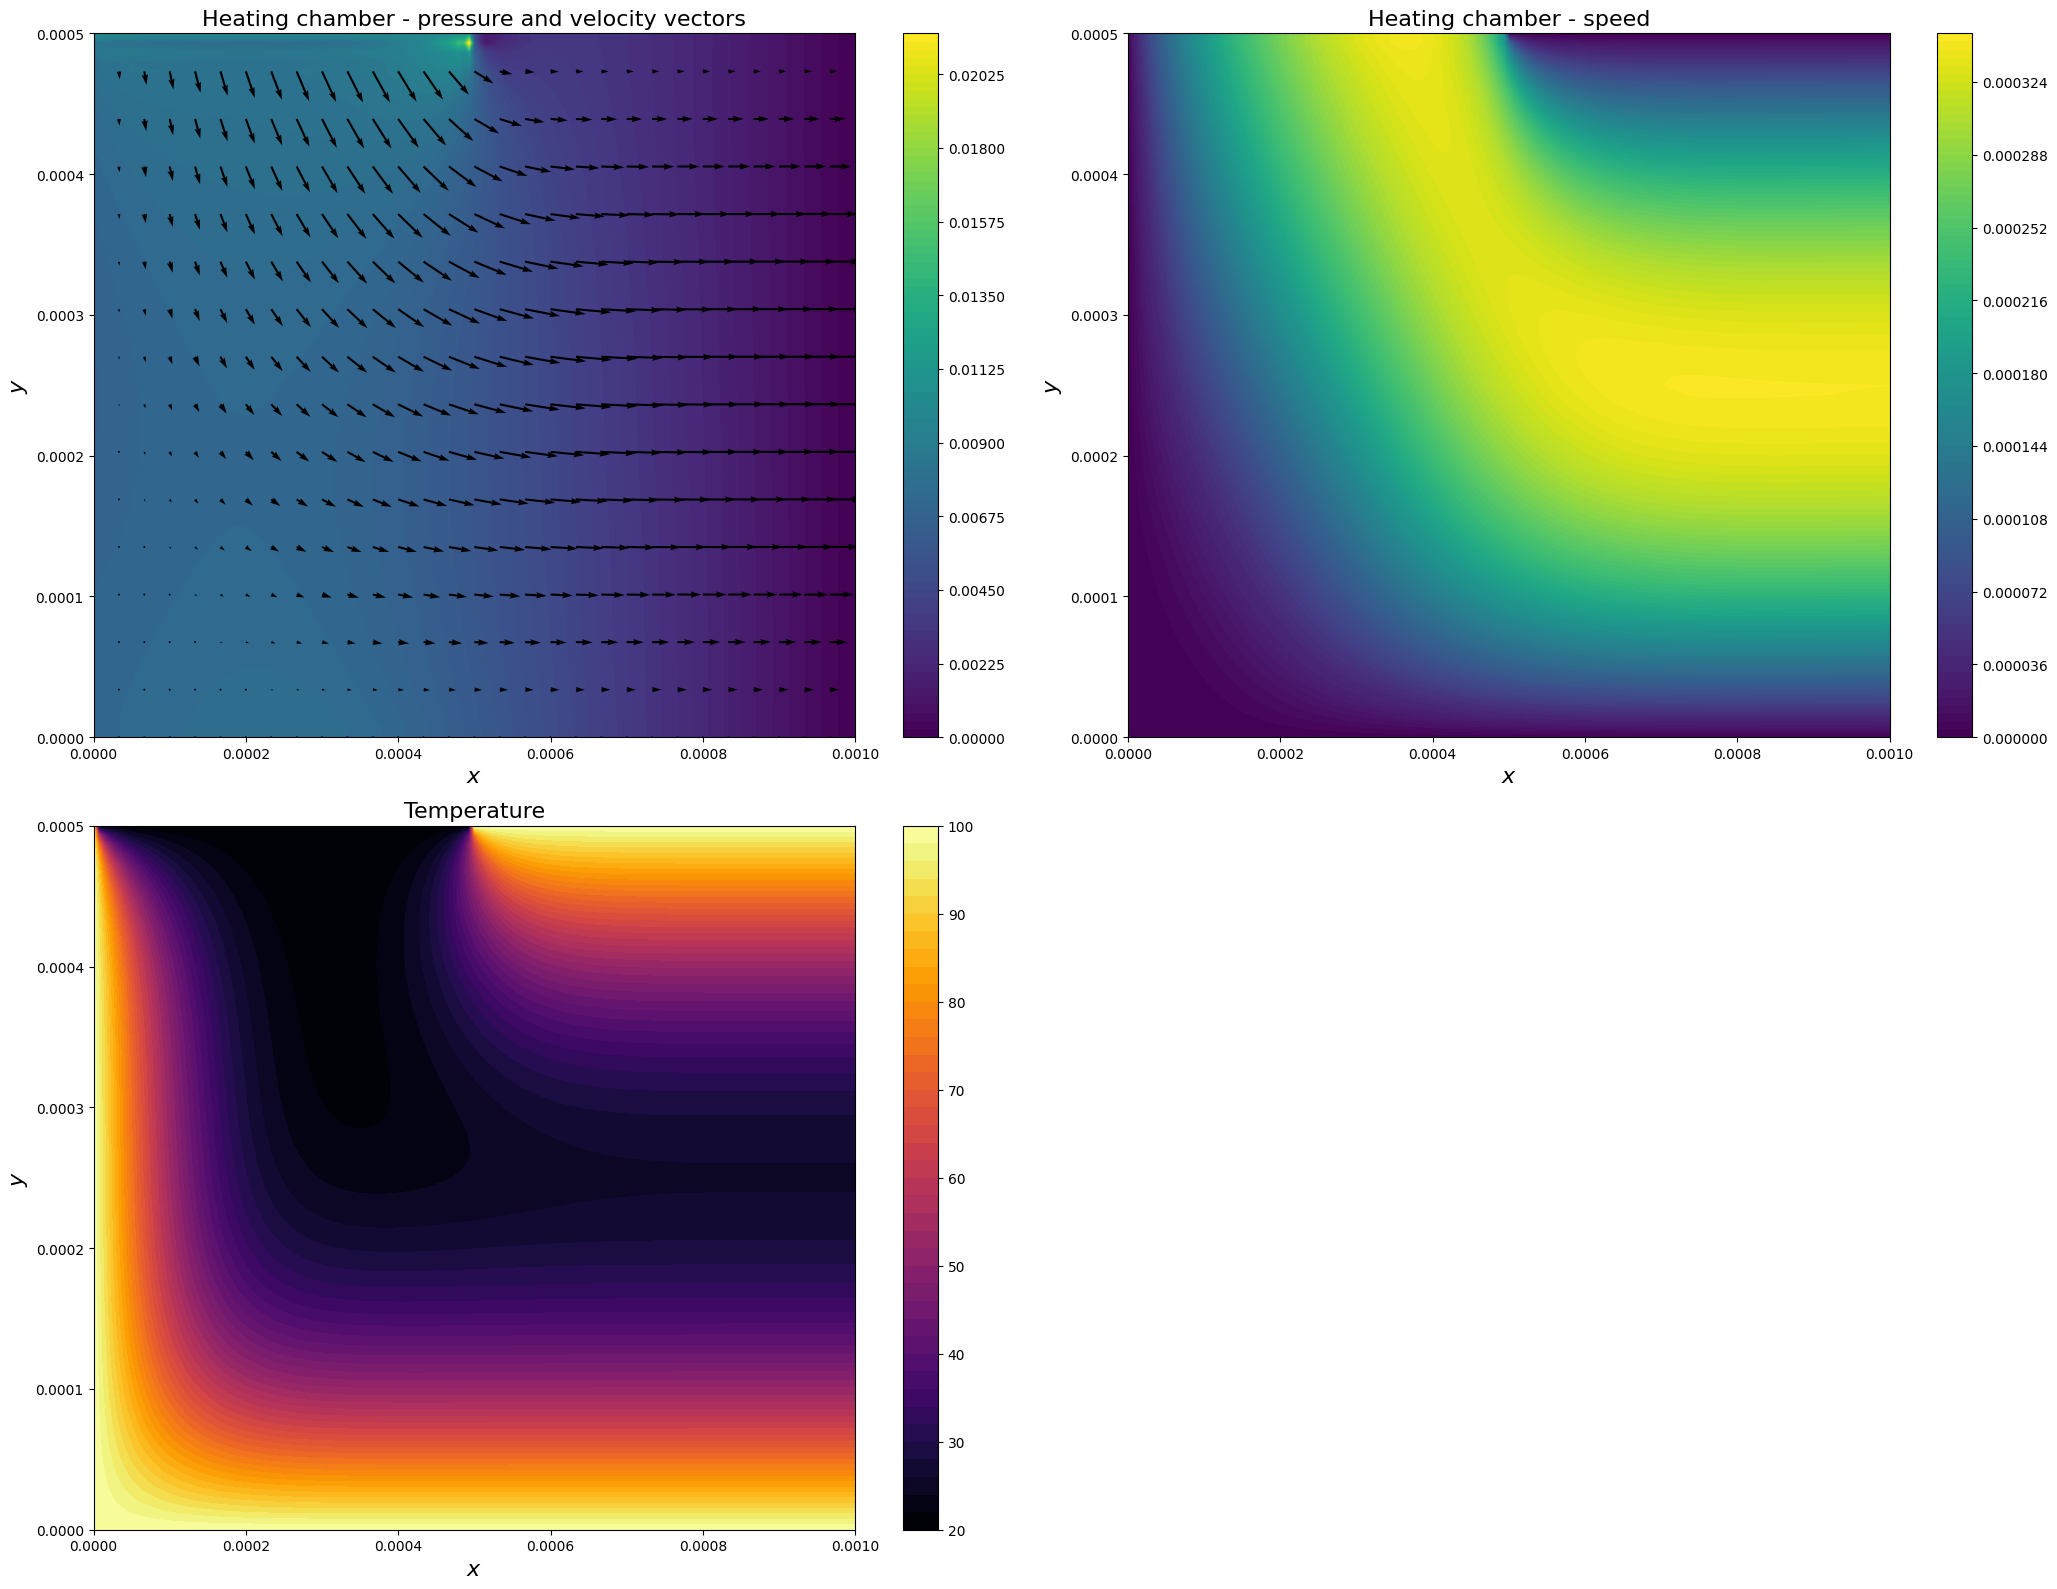

In [18]:
run_sim(microwave_power=1)

Courant number criterion: 0.0193618
Diffusivity criterion: 0.0001556
Temperature range: [20.00, 117.07]°C
Average x-velocity: 2.00e-04 m/s, Average x-velocity: 9.81e-05 m/s, Average temperature: 99.3 deg
Time taken by calculation = 40.5601
Out Flow: 102.13 deg
In Flow: 20.00 deg
Reynolds number: 0.2263
Peclet number: 1.5843
Damkohler number: 78.8998
Flow in Rate: 1.138e-07 m²/s
Flow out Rate: 1.147e-07 m²/s


(1.584, 102.129)

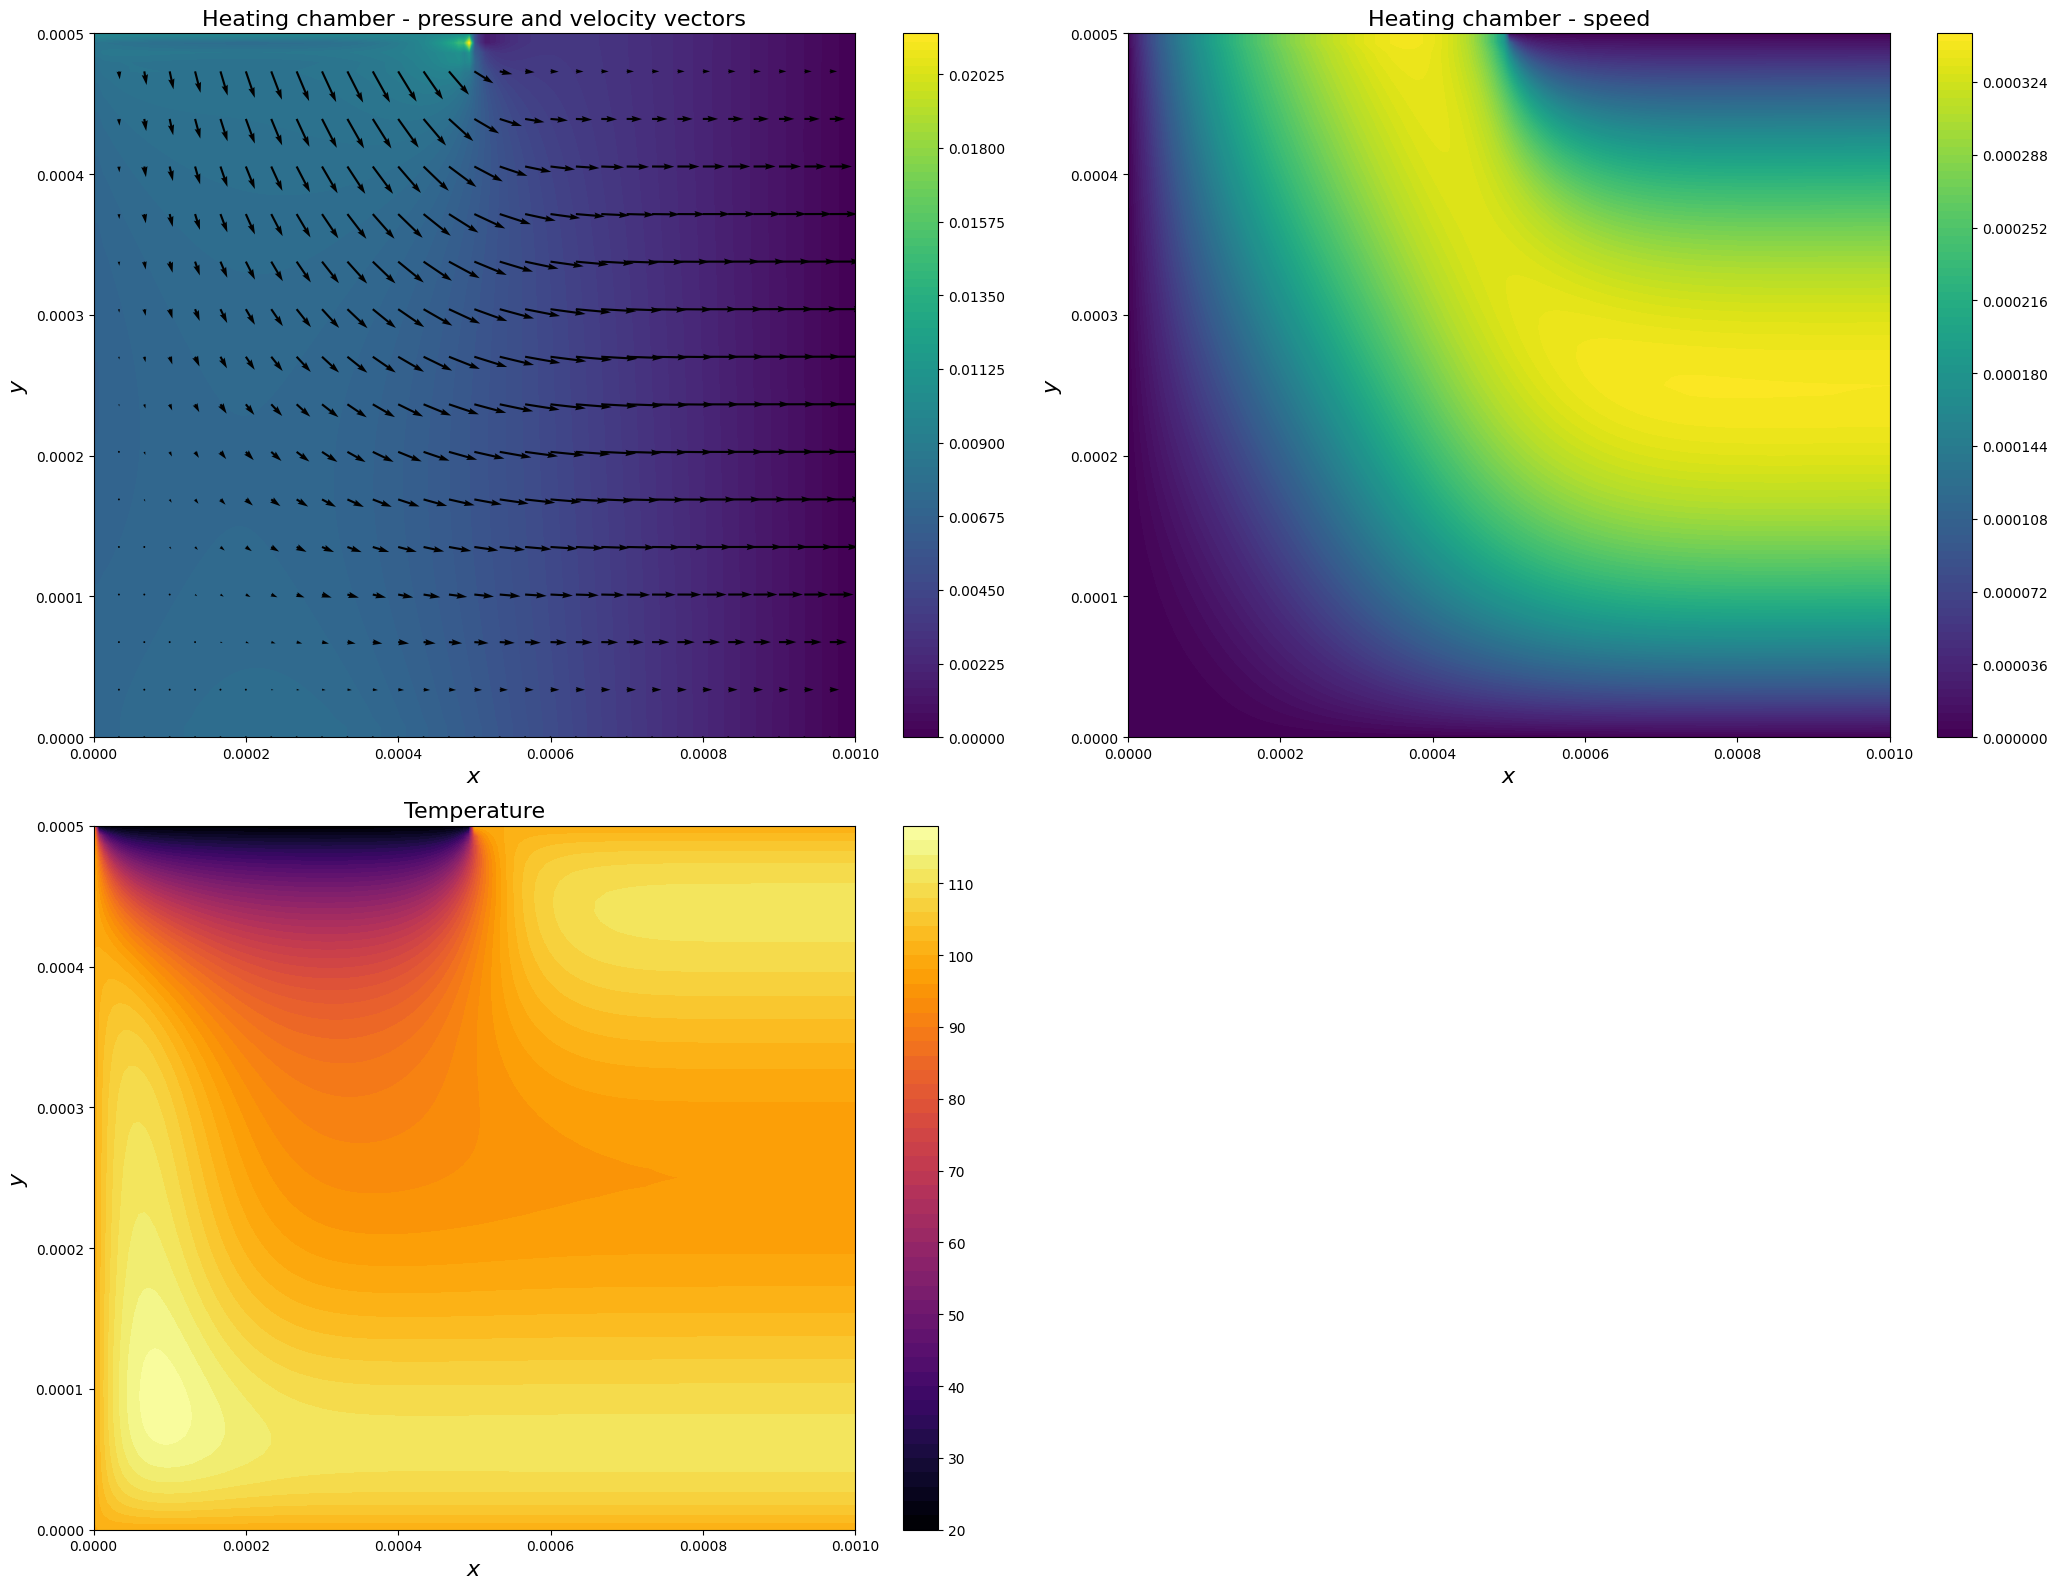

In [19]:
run_sim(microwave_power=3000)

### Analysis of flow at different Da

At Da << 1 there is no time for significant heating to take place, indicated by the black unheated core. At Da >> 1, the water spends so much time in the reactor that it is close to reaching thermal equilibrium, indicated by relatively small temperature gradients (compared to those near the inlet) in the middle of the flow. Neither of these extremes are useful for a practical application.

### Improvements

Improvements of the simulation include a better initialisation of pressure (e.g. linear) and temperature for faster convergence, use of higher order schemes, using shifted grids for pressure and velocity, implementing a variable timestep (dependent on CFL or diffusion condition) and introducing a two-way coupling between velocity and temperature (currently only temperature depends on velocity, but not the other way around).